In [1]:
import sys
from pathlib import Path
import torch.nn.functional as F 

# Make the repo root importable so `src.…` resolves (notebooks run from prototyping/)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.backbones.vit_vqvae import ViTVQVAE
from src.utils.dataloader import ImageData


In [2]:
data = ImageData(batch_size=32)
model = ViTVQVAE(dead_code_threshold=1.0, num_codes=64)     # Dead codebook restarts off (Matching CNN baseline)

In [3]:
import torch
from src.utils.device import get_device


def train(model: ViTVQVAE, data: ImageData, learning_rate: float, epochs: int, max_steps: int | None = None):
    """Pure-reconstruction regime: loss = MSE(reconstruction, target) + VQ loss.

    max_steps: stop each epoch early after this many batches (for quick debugging).
    """
    device = get_device()
    model.to(device).train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

    for epoch in range(epochs):
        for step, (images_in, images_out, _labels) in enumerate(data.train_loader):
            images_in = images_in.to(device)
            images_out = images_out.to(device)   # target: may be a different colour space (e.g. rgb2ycbcr)

            prediction = model(images_in)
            mse_loss = F.mse_loss(prediction["reconstruction"], images_out)
            vq_loss = prediction["vq_loss"]      # codebook loss + beta * commitment loss
            loss = mse_loss + vq_loss

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            print(
                f"epoch {epoch} step {step}: loss {loss.item():.4f} "
                f"(mse {mse_loss.item():.4f}, vq {vq_loss.item():.4f}) "
                f"perplexity {prediction['perplexity'].item():.2f} "
                f"active {prediction['active_codes'].item():.0%}"
            )
            if max_steps is not None and step + 1 >= max_steps:
                break


In [4]:
model.train()
train(model=model, data=data, learning_rate=1e-4, epochs=5)

epoch 0 step 0: loss 0.6745 (mse 0.6744, vq 0.0001) perplexity 43.83 active 100%
epoch 0 step 1: loss 0.5991 (mse 0.5987, vq 0.0004) perplexity 24.59 active 86%
epoch 0 step 2: loss 0.5233 (mse 0.5229, vq 0.0005) perplexity 22.74 active 70%
epoch 0 step 3: loss 0.5314 (mse 0.5308, vq 0.0006) perplexity 14.70 active 58%
epoch 0 step 4: loss 0.4760 (mse 0.4754, vq 0.0006) perplexity 13.65 active 62%
epoch 0 step 5: loss 0.4264 (mse 0.4257, vq 0.0006) perplexity 14.89 active 58%
epoch 0 step 6: loss 0.4547 (mse 0.4541, vq 0.0007) perplexity 9.42 active 36%
epoch 0 step 7: loss 0.4056 (mse 0.4051, vq 0.0006) perplexity 2.71 active 27%
epoch 0 step 8: loss 0.3981 (mse 0.3974, vq 0.0006) perplexity 3.61 active 27%
epoch 0 step 9: loss 0.3719 (mse 0.3717, vq 0.0002) perplexity 2.48 active 17%
epoch 0 step 10: loss 0.3989 (mse 0.3987, vq 0.0003) perplexity 3.33 active 17%
epoch 0 step 11: loss 0.3728 (mse 0.3725, vq 0.0002) perplexity 3.32 active 23%
epoch 0 step 12: loss 0.3747 (mse 0.3745, v

In [6]:
checkpoint_dir = REPO_ROOT / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "vit_vqvae_5_epoch_64_K_w_restarts.pt"
torch.save(model.state_dict(), checkpoint_path)

print(f"Saved checkpoint to {checkpoint_path}")


Saved checkpoint to /Users/jairo/.workspace/spatiochromatic-vit-vqvae/checkpoints/vit_vqvae_5_epoch_64_K_w_restarts.pt


In [7]:
# Codebook swatches: fill the whole latent grid with code i and decode it.
# The decoder wants quantised tokens (B, N, D), not indices, so go through decode_from_indices.
model.eval()
device = next(model.parameters()).device
K, g = model.num_codes, model.grid_size

grid = torch.arange(K, device=device).view(K, 1, 1).expand(K, g, g)   # (K, h, w), code i everywhere
swatches = model.decode_from_indices(grid)                            # (K, C, H, W) in [-1, 1]
print(swatches.shape)

torch.Size([64, 3, 224, 224])




In [8]:
import matplotlib.pyplot as plt
from src.utils.dataloader import denormalise
from src.colour_spaces import COLOUR_SPACES

images = denormalise(swatches).cpu()
to_rgb = COLOUR_SPACES[data.train_data.out_space].to_rgb   # e.g. YCbCr target -> RGB for display
if to_rgb is not None:
    images = to_rgb(images)

usage = model.quantizer.usage.cpu()   # running average of tokens per batch that pick each code
fig, axes = plt.subplots(1, K, figsize=(2 * K, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(images[i].clamp(0, 1).permute(1, 2, 0))
    ax.set_title(f"code {i}\nuse {usage[i]:.0f}", fontsize=13)
    ax.axis("off")
plt.tight_layout()
plt.show()

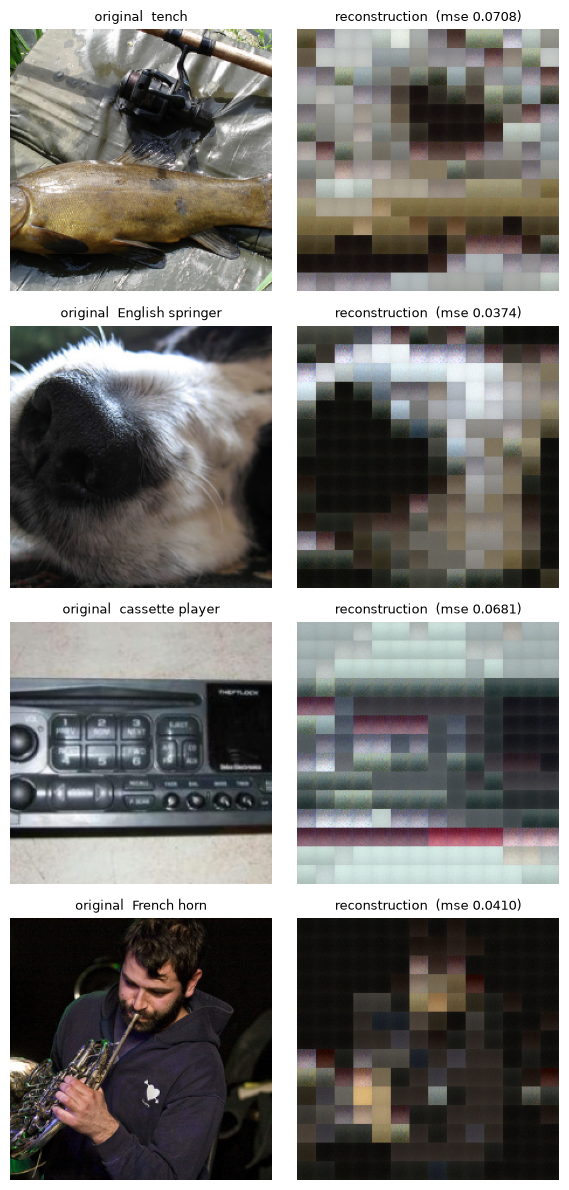

In [9]:
@torch.no_grad()
def show_reconstructions(model: ViTVQVAE, dataset, indices: list[int]) -> None:
    """Plot target (left) and reconstruction (right) for each sample index, both shown in RGB."""
    model.eval()
    device = next(model.parameters()).device
    to_rgb = COLOUR_SPACES[dataset.out_space].to_rgb

    def for_display(image: torch.Tensor) -> torch.Tensor:
        image = denormalise(image.cpu())
        if to_rgb is not None:
            image = to_rgb(image)
        return image.clamp(0, 1).permute(1, 2, 0)

    samples = [dataset[i] for i in indices]
    images_in = torch.stack([s[0] for s in samples]).to(device)
    targets = torch.stack([s[1] for s in samples]).to(device)
    reconstructions = model(images_in)["reconstruction"]

    classes = getattr(dataset.base, "classes", None)
    fig, axes = plt.subplots(len(indices), 2, figsize=(6, 3 * len(indices)), squeeze=False)
    for row, (target, recon, (_, _, label)) in enumerate(zip(targets, reconstructions, samples)):
        name = ""
        if classes and label >= 0:
            name = classes[label]
            name = name[0] if isinstance(name, tuple) else name   # Imagenette gives tuples of synonyms
        mse = F.mse_loss(recon, target).item()

        axes[row, 0].imshow(for_display(target))
        axes[row, 0].set_title(f"original  {name}", fontsize=9)
        axes[row, 1].imshow(for_display(recon))
        axes[row, 1].set_title(f"reconstruction  (mse {mse:.4f})", fontsize=9)
        for ax in axes[row]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()


show_reconstructions(model, data.val_data, indices=[0, 500, 1000, 2000])

In [5]:
with torch.no_grad():
    _x, _y, _ = next(iter(data.val_loader))
    _dev = next(model.parameters()).device
    _out = model.eval()(_x.to(_dev))
    _r = _out["reconstruction"].cpu()
    _p = model.patch_size
    def _within_patch_std(im):   # std of pixels inside each P x P patch, averaged
        return im.unfold(2, _p, _p).unfold(3, _p, _p).std(dim=(-1, -2)).mean().item()
    print("output shape:", tuple(_r.shape), "patch:", _p, "grid:", model.grid_size, "K:", model.num_codes)
    print(f"within-patch std  target {_within_patch_std(_y):.4f}  recon {_within_patch_std(_r):.4f}")
    print(f"global std        target {_y.std():.4f}  recon {_r.std():.4f}")
    print("perplexity", _out["perplexity"].item(), "active", _out["active_codes"].item())
    print("usage", model.quantizer.usage.cpu().numpy().round(1))
    print("compression ratio", round(model.bit_compression_ratio()))

output shape: (32, 3, 224, 224) patch: 16 grid: 14 K: 64
within-patch std  target 0.2218  recon 0.0724
global std        target 0.5138  recon 0.4596
perplexity 45.0655632019043 active 0.96875
usage [ 65.8   7.   48.3 153.  111.2  69.4  86.9  56.6  65.8 108.6 121.  138.2
  63.   73.4 145.1 116.5  61.5  54.8 175.6  42.4 116.2  67.3  98.5 171.4
 136.6 144.6 258.7  95.4 403.2 115.3   6.9 113.8  64.9  87.6  71.6  66.
 120.9  90.6 145.7 265.1   5.5  88.1  33.8  79.1  81.3  36.8 168.4  33.2
 184.5  56.4 132.9 198.4  54.   52.   53.3 185.3  67.5  22.6  19.7  41.6
  80.1   5.2  35.9 145.6]
compression ratio 1024
